Device: cpu
Dataset: (400, 16, 16, 3)


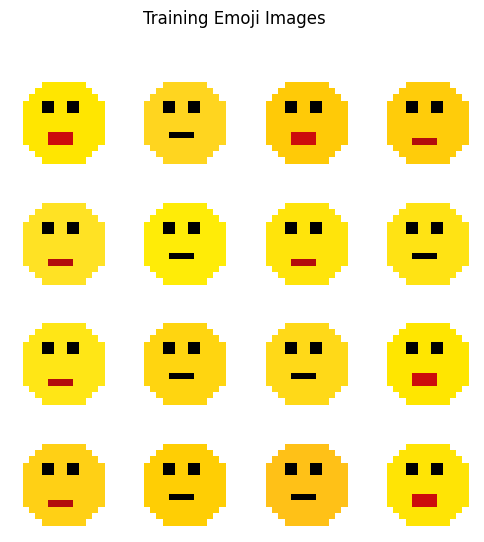


Training started...

Epoch 01/15 | G Loss: 0.573 | D Loss: 0.669
Epoch 02/15 | G Loss: 0.848 | D Loss: 0.430
Epoch 03/15 | G Loss: 1.084 | D Loss: 0.340
Epoch 04/15 | G Loss: 1.465 | D Loss: 0.225
Epoch 05/15 | G Loss: 1.718 | D Loss: 0.174
Epoch 06/15 | G Loss: 1.901 | D Loss: 0.150
Epoch 07/15 | G Loss: 1.911 | D Loss: 0.154
Epoch 08/15 | G Loss: 2.041 | D Loss: 0.140
Epoch 09/15 | G Loss: 1.980 | D Loss: 0.158
Epoch 10/15 | G Loss: 1.905 | D Loss: 0.188
Epoch 11/15 | G Loss: 1.735 | D Loss: 0.237
Epoch 12/15 | G Loss: 1.646 | D Loss: 0.274
Epoch 13/15 | G Loss: 1.607 | D Loss: 0.293
Epoch 14/15 | G Loss: 1.633 | D Loss: 0.302
Epoch 15/15 | G Loss: 1.575 | D Loss: 0.312

Training completed!


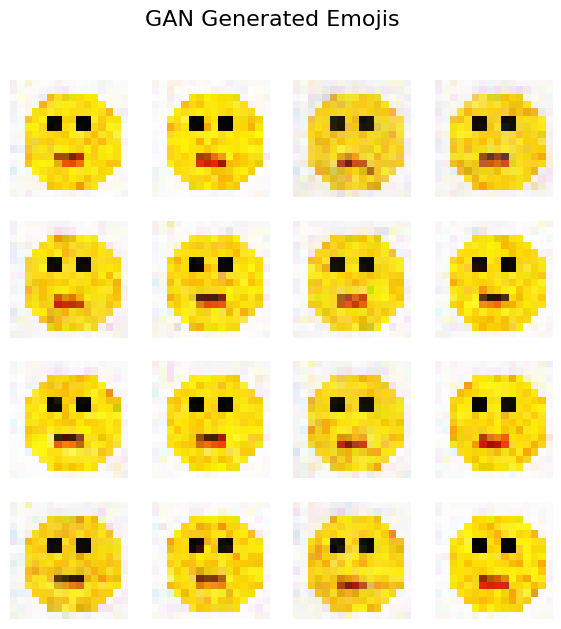

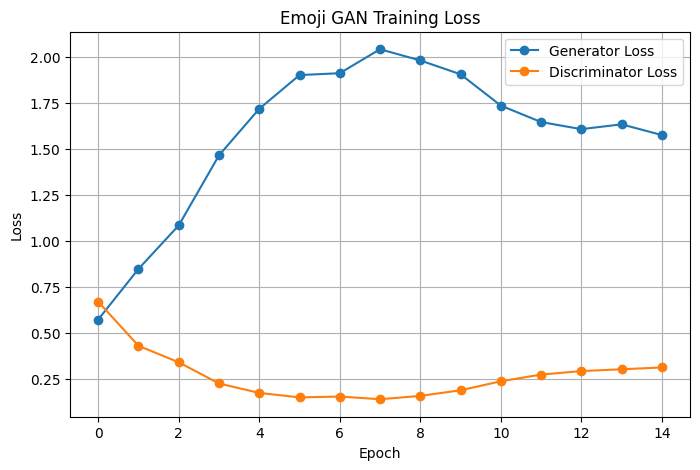


      EMOJI GAN COMPLETE


In [1]:
# ============================================================
# FAST EMOJI GAN - IMPROVED VERSION
# Google Colab
# No files / No external dataset
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

np.random.seed(10)
torch.manual_seed(10)

IMG_SIZE = 16
LATENT = 20

N_IMAGES = 400
BATCH_SIZE = 32
EPOCHS = 15

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 2. CREATE EMOJI DATASET
# ============================================================

def make_emoji():

    img = np.ones(
        (IMG_SIZE, IMG_SIZE, 3),
        dtype=np.float32
    )

    # --------------------------
    # Yellow face
    # --------------------------

    yellow = [
        1.0,
        np.random.uniform(0.75, 0.95),
        np.random.uniform(0.0, 0.15)
    ]

    for x in range(IMG_SIZE):

        for y in range(IMG_SIZE):

            if (x - 8)**2 + (y - 8)**2 <= 45:

                img[x, y] = yellow

    # --------------------------
    # Eyes
    # --------------------------

    img[5:7, 5:7] = 0
    img[5:7, 9:11] = 0

    # --------------------------
    # Different expressions
    # --------------------------

    expression = np.random.randint(3)

    if expression == 0:

        # Happy
        img[10:12, 6:10] = [
            0.8, 0.05, 0.05
        ]

    elif expression == 1:

        # Normal
        img[10:11, 6:10] = 0

    else:

        # Sad
        img[11:12, 6:10] = [
            0.7, 0.05, 0.05
        ]

    return img


# Create images
images = np.array([
    make_emoji()
    for _ in range(N_IMAGES)
])

print("Dataset:", images.shape)


# ============================================================
# 3. SHOW TRAINING EMOJIS
# ============================================================

plt.figure(figsize=(6, 6))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    plt.imshow(images[i])

    plt.axis("off")

plt.suptitle("Training Emoji Images")

plt.show()


# ============================================================
# 4. PREPARE DATA
# ============================================================

# Convert 0-1 → -1 to 1
images = images * 2 - 1

# Convert HWC → CHW for PyTorch
images = torch.tensor(
    images,
    dtype=torch.float32
).permute(0, 3, 1, 2)


# ============================================================
# 5. GENERATOR
# ============================================================

class Generator(nn.Module):

    def __init__(self):

        super().__init__()

        self.model = nn.Sequential(

            nn.Linear(LATENT, 128 * 4 * 4),

            nn.BatchNorm1d(128 * 4 * 4),

            nn.ReLU(True),

            nn.Unflatten(
                1,
                (128, 4, 4)
            ),

            nn.ConvTranspose2d(
                128,
                64,
                4,
                2,
                1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(True),

            nn.ConvTranspose2d(
                64,
                32,
                4,
                2,
                1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(True),

            nn.Conv2d(
                32,
                3,
                3,
                padding=1
            ),

            nn.Tanh()
        )

    def forward(self, x):

        return self.model(x)


# ============================================================
# 6. DISCRIMINATOR
# ============================================================

class Discriminator(nn.Module):

    def __init__(self):

        super().__init__()

        self.model = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                4,
                2,
                1
            ),

            nn.LeakyReLU(
                0.2,
                inplace=True
            ),

            nn.Conv2d(
                32,
                64,
                4,
                2,
                1
            ),

            nn.BatchNorm2d(64),

            nn.LeakyReLU(
                0.2,
                inplace=True
            ),

            nn.Flatten(),

            nn.Linear(
                64 * 4 * 4,
                1
            )
        )

    def forward(self, x):

        return self.model(x)


G = Generator().to(device)
D = Discriminator().to(device)


# ============================================================
# 7. LOSS + OPTIMIZERS
# ============================================================

loss_fn = nn.BCEWithLogitsLoss()

G_optimizer = torch.optim.Adam(
    G.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

D_optimizer = torch.optim.Adam(
    D.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)


# ============================================================
# 8. TRAINING
# ============================================================

G_losses = []
D_losses = []

print("\nTraining started...\n")

for epoch in range(EPOCHS):

    indices = torch.randperm(N_IMAGES)

    g_total = 0
    d_total = 0
    count = 0

    for start in range(
        0,
        N_IMAGES,
        BATCH_SIZE
    ):

        idx = indices[
            start:start + BATCH_SIZE
        ]

        real = images[idx].to(device)

        batch_size = real.size(0)

        # ------------------------------------------------
        # Train Discriminator
        # ------------------------------------------------

        noise = torch.randn(
            batch_size,
            LATENT,
            device=device
        )

        fake = G(noise)

        real_labels = torch.ones(
            batch_size,
            1,
            device=device
        )

        fake_labels = torch.zeros(
            batch_size,
            1,
            device=device
        )

        real_output = D(real)

        fake_output = D(
            fake.detach()
        )

        real_loss = loss_fn(
            real_output,
            real_labels
        )

        fake_loss = loss_fn(
            fake_output,
            fake_labels
        )

        D_loss = (
            real_loss + fake_loss
        ) / 2

        D_optimizer.zero_grad()

        D_loss.backward()

        D_optimizer.step()

        # ------------------------------------------------
        # Train Generator
        # ------------------------------------------------

        noise = torch.randn(
            batch_size,
            LATENT,
            device=device
        )

        fake = G(noise)

        output = D(fake)

        G_loss = loss_fn(
            output,
            real_labels
        )

        G_optimizer.zero_grad()

        G_loss.backward()

        G_optimizer.step()

        g_total += G_loss.item()
        d_total += D_loss.item()

        count += 1

    g_avg = g_total / count
    d_avg = d_total / count

    G_losses.append(g_avg)
    D_losses.append(d_avg)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"G Loss: {g_avg:.3f} | "
        f"D Loss: {d_avg:.3f}"
    )


print("\nTraining completed!")


# ============================================================
# 9. GENERATE NEW EMOJIS
# ============================================================

noise = torch.randn(
    16,
    LATENT,
    device=device
)

with torch.no_grad():

    generated = G(noise)

# CHW → HWC
generated = generated.cpu().permute(
    0, 2, 3, 1
)

# -1 to 1 → 0 to 1
generated = (
    generated + 1
) / 2

generated = torch.clamp(
    generated,
    0,
    1
)


# ============================================================
# 10. SHOW GENERATED EMOJIS
# ============================================================

plt.figure(figsize=(7, 7))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    plt.imshow(
        generated[i].numpy()
    )

    plt.axis("off")

plt.suptitle(
    "GAN Generated Emojis",
    fontsize=16
)

plt.show()


# ============================================================
# 11. LOSS GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    G_losses,
    marker="o",
    label="Generator Loss"
)

plt.plot(
    D_losses,
    marker="o",
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Emoji GAN Training Loss"
)

plt.legend()

plt.grid()

plt.show()


print("\n================================")
print("      EMOJI GAN COMPLETE")
print("================================")